<h1>IMPORTAÇÃO DE BIBLIOTECAS</h1>

In [32]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestClassifier

from imblearn.over_sampling import SMOTE

from sklearn import tree

<h1>Criação de Pipelines </h1>

In [33]:
preprocessing_path = "./preprocessing/"

preprocessing_dataset_fileName = "05-preprocessing_dataset.csv"
ml_classification_dataset_filename = "06-ml_models_dataset.csv"
dense_classification_dataset_filename = "06-dense_modles_dataset.csv"

df_dataset = pd.read_csv(preprocessing_path+preprocessing_dataset_fileName)
df_dataset.info()

def printDesempenho(y_train, y_train_pred, y_test, y_test_pred, encoder_y):
    print("TREINAMENTO:")
    print(classification_report(y_train, y_train_pred, target_names=encoder_y.classes_, digits=4))
    print("TESTE:")
    print(classification_report(y_test, y_test_pred, target_names=encoder_y.classes_,digits=4))

<class 'pandas.DataFrame'>
RangeIndex: 13830 entries, 0 to 13829
Data columns (total 31 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   dataName              13830 non-null  str    
 1   motorSpeed            13830 non-null  float64
 2   load                  13830 non-null  float64
 3   class                 13830 non-null  str    
 4   rawData               13830 non-null  str    
 5   I_kurtosis            13830 non-null  float64
 6   I_max                 13830 non-null  float64
 7   I_median              13830 non-null  float64
 8   I_mode                13830 non-null  float64
 9   I_skewness            13830 non-null  float64
 10  Q_kurtosis            13830 non-null  float64
 11  Q_max                 13830 non-null  float64
 12  Q_min                 13830 non-null  float64
 13  Q_mode                13830 non-null  float64
 14  Q_skewness            13830 non-null  float64
 15  Q_std                 13830 no

In [34]:
d = df_dataset.select_dtypes('number')
d.info()

<class 'pandas.DataFrame'>
RangeIndex: 13830 entries, 0 to 13829
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   motorSpeed            13830 non-null  float64
 1   load                  13830 non-null  float64
 2   I_kurtosis            13830 non-null  float64
 3   I_max                 13830 non-null  float64
 4   I_median              13830 non-null  float64
 5   I_mode                13830 non-null  float64
 6   I_skewness            13830 non-null  float64
 7   Q_kurtosis            13830 non-null  float64
 8   Q_max                 13830 non-null  float64
 9   Q_min                 13830 non-null  float64
 10  Q_mode                13830 non-null  float64
 11  Q_skewness            13830 non-null  float64
 12  Q_std                 13830 non-null  float64
 13  module_kurtosis       13830 non-null  float64
 14  module_max            13830 non-null  float64
 15  module_min            13830 no

In [35]:
encoder_data = MinMaxScaler()
encoder_class = LabelEncoder()
balanceamento = SMOTE(random_state=42)

X = df_dataset.select_dtypes(include="number")
Y = df_dataset['class']
x_encoded = encoder_data.fit_transform(X)
y_encoded = encoder_class.fit_transform(Y)

X_train, X_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.3, random_state=0, stratify=y_encoded)

#balanceamento
X_train_resampled, y_train_resampled = balanceamento.fit_resample(X_train, y_train)


<h1>Gaussian NB</h1>

In [36]:
model_gaussianNB1 = GaussianNB()

model_gaussianNB1.fit(X_train_resampled, y_train_resampled)
y_train_pred = model_gaussianNB1.predict(X_train)
y_test_pred = model_gaussianNB1.predict(X_test)

printDesempenho(y_train, y_train_pred, y_test, y_test_pred, encoder_class)


TREINAMENTO:
              precision    recall  f1-score   support

     Bearing     0.8056    0.8730    0.8380      1386
   Imbalance     0.9145    0.8776    0.8957      4158
      Normal     0.9985    0.9711    0.9846      1386
       Rotor     0.8042    0.8947    0.8470      1386
       Wound     1.0000    0.9516    0.9752      1365

    accuracy                         0.9032      9681
   macro avg     0.9046    0.9136    0.9081      9681
weighted avg     0.9072    0.9032    0.9044      9681

TESTE:
              precision    recall  f1-score   support

     Bearing     0.8028    0.8771    0.8383       594
   Imbalance     0.9152    0.8782    0.8963      1782
      Normal     1.0000    0.9697    0.9846       594
       Rotor     0.7857    0.8704    0.8259       594
       Wound     1.0000    0.9504    0.9746       585

    accuracy                         0.9002      4149
   macro avg     0.9007    0.9092    0.9039      4149
weighted avg     0.9047    0.9002    0.9016      4149



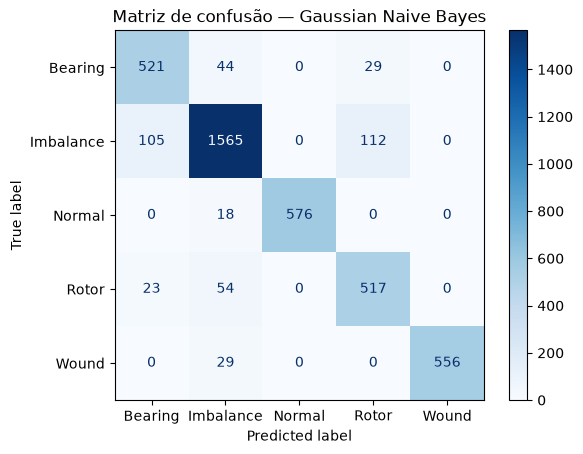

In [37]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    display_labels=encoder_class.classes_,
    cmap="Blues"
)

plt.title("Matriz de confusão — Gaussian Naive Bayes")
plt.show()

In [38]:
model_gaussianNB2 = GaussianNB()

model_gaussianNB2.fit(x_encoded, y_encoded)
y_pred = model_gaussianNB2.predict(x_encoded)
print(classification_report(y_encoded, y_pred, target_names=encoder_class.classes_))

              precision    recall  f1-score   support

     Bearing       0.82      0.86      0.84      1980
   Imbalance       0.91      0.88      0.90      5940
      Normal       1.00      0.97      0.99      1980
       Rotor       0.80      0.88      0.84      1980
       Wound       1.00      0.95      0.98      1950

    accuracy                           0.90     13830
   macro avg       0.90      0.91      0.91     13830
weighted avg       0.91      0.90      0.90     13830



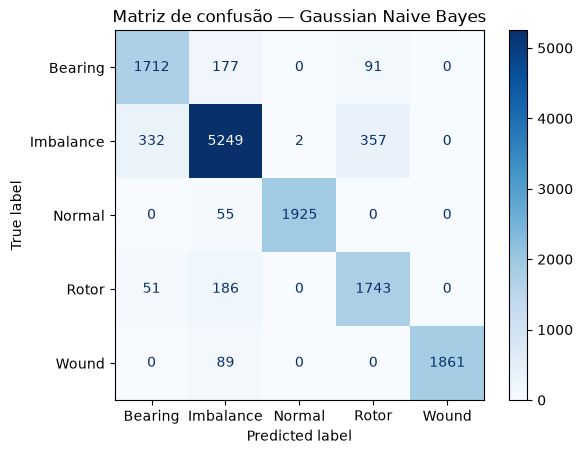

In [39]:
y_pred = model_gaussianNB2.predict(x_encoded)
ConfusionMatrixDisplay.from_predictions(
    y_encoded,
    y_pred,
    display_labels=encoder_class.classes_,
    cmap="Blues"
)

plt.title("Matriz de confusão — Gaussian Naive Bayes")
plt.show()

<h1>Arvore de Decisão</h1>

In [40]:
pipeline_machineLearning = Pipeline([
    ("modelo", DecisionTreeClassifier())
])

param_grid = [
    {
        "modelo":[DecisionTreeClassifier(random_state=0)],
        "modelo__criterion": ['gini', 'entropy'],
        "modelo__max_depth": np.arange(1,10)
    }
]

grid_search = GridSearchCV(
    pipeline_machineLearning,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_resampled, y_train_resampled)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo': [DecisionTreeC...andom_state=0)], 'modelo__criterion': ['gini', 'entropy'], 'modelo__max_depth': array([1, 2, ..., 6, 7, 8, 9])}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callab

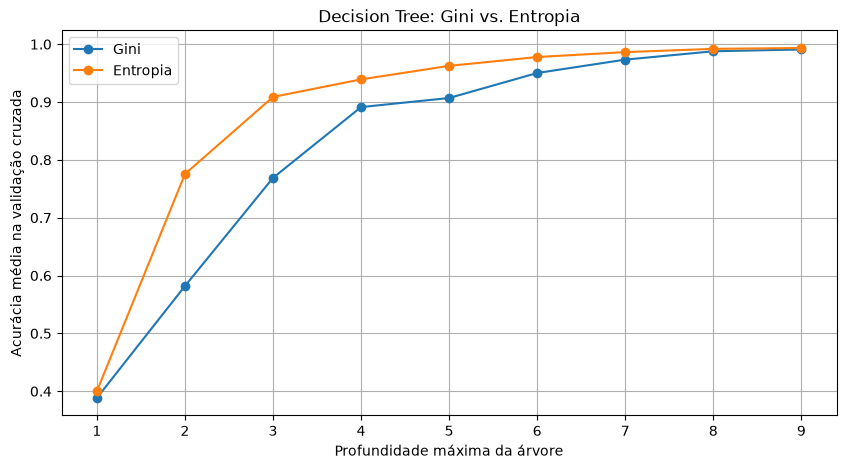

In [41]:
results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(10, 5))

gini = results[
    results["param_modelo__criterion"] == "gini"
]

entropy = results[
    results["param_modelo__criterion"] == "entropy"
]

plt.plot(
    gini["param_modelo__max_depth"],
    gini["mean_test_score"],
    marker="o",
    label="Gini"
)

plt.plot(
    entropy["param_modelo__max_depth"],
    entropy["mean_test_score"],
    marker="o",
    label="Entropia"
)

plt.xlabel("Profundidade máxima da árvore")
plt.ylabel("Acurácia média na validação cruzada")
plt.title("Decision Tree: Gini vs. Entropia")
plt.legend()
plt.grid()
plt.show()

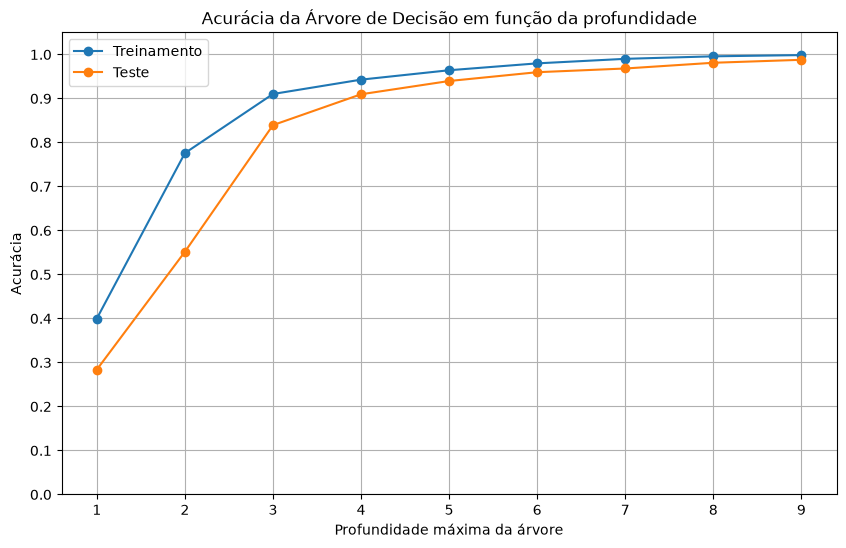

In [42]:
from sklearn.metrics import accuracy_score
profundidades = range(1, 10)

acuracias_treino = []
acuracias_teste = []

for profundidade in profundidades:

    modelo = DecisionTreeClassifier(
        max_depth=profundidade,
        criterion='entropy',
        random_state=42
    )

    modelo.fit(X_train_resampled, y_train_resampled)

    # Acurácia no treinamento
    y_train_pred = modelo.predict(X_train_resampled)
    acc_train = accuracy_score(y_train_resampled, y_train_pred)

    # Acurácia no teste
    y_test_pred = modelo.predict(X_test)
    acc_test = accuracy_score(y_test, y_test_pred)

    acuracias_treino.append(acc_train)
    acuracias_teste.append(acc_test)

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(
    profundidades,
    acuracias_treino,
    marker="o",
    label="Treinamento"
)

plt.plot(
    profundidades,
    acuracias_teste,
    marker="o",
    label="Teste"
)

plt.xlabel("Profundidade máxima da árvore")
plt.ylabel("Acurácia")
plt.title("Acurácia da Árvore de Decisão em função da profundidade")
plt.ylim(0, 1)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(profundidades)
plt.ylim(0, 1.05)
plt.grid()
plt.legend()

plt.show()

In [43]:
print(pd.DataFrame(data={"profundidade": profundidades, "treino": acuracias_treino, "teste": acuracias_teste}))

   profundidade    treino     teste
0             1  0.399952  0.283924
1             2  0.775902  0.551699
2             3  0.910245  0.839479
3             4  0.942857  0.909617
4             5  0.964214  0.939745
5             6  0.979846  0.959749
6             7  0.990139  0.968185
7             8  0.995863  0.981200
8             9  0.998653  0.987949


In [44]:
print(grid_search.best_params_)

y_train_pred = grid_search.predict(X_train)
y_test_pred = grid_search.predict(X_test)
printDesempenho(y_train, y_train_pred, y_test, y_test_pred, encoder_class)

{'modelo': DecisionTreeClassifier(random_state=0), 'modelo__criterion': 'entropy', 'modelo__max_depth': np.int64(9)}
TREINAMENTO:
              precision    recall  f1-score   support

     Bearing     0.9864    0.9978    0.9921      1386
   Imbalance     0.9993    0.9957    0.9975      4158
      Normal     1.0000    1.0000    1.0000      1386
       Rotor     1.0000    0.9993    0.9996      1386
       Wound     1.0000    1.0000    1.0000      1365

    accuracy                         0.9977      9681
   macro avg     0.9971    0.9986    0.9978      9681
weighted avg     0.9977    0.9977    0.9977      9681

TESTE:
              precision    recall  f1-score   support

     Bearing     0.9734    0.9865    0.9799       594
   Imbalance     0.9881    0.9826    0.9854      1782
      Normal     0.9983    0.9916    0.9949       594
       Rotor     0.9783    0.9848    0.9815       594
       Wound     0.9966    1.0000    0.9983       585

    accuracy                         0.9872     

[Text(0.6041666666666666, 0.9, 'Q_skewness <= 0.451\nsamples = 20790\nvalue = [4158, 4158, 4158, 4158, 4158]\nclass = Bearing'),
 Text(0.3333333333333333, 0.7, 'I_kurtosis <= 0.364\nsamples = 12248\nvalue = [4081.0, 3799.0, 209.0, 4158.0, 1.0]\nclass = Rotor'),
 Text(0.46875, 0.8, 'True  '),
 Text(0.16666666666666666, 0.5, 'module_skewness <= 0.607\nsamples = 4721\nvalue = [23, 708, 23, 3967, 0]\nclass = Rotor'),
 Text(0.08333333333333333, 0.3, 'module_kurtosis <= 0.303\nsamples = 549\nvalue = [0, 473, 23, 53, 0]\nclass = Imbalance'),
 Text(0.041666666666666664, 0.1, '\n  (...)  \n'),
 Text(0.125, 0.1, '\n  (...)  \n'),
 Text(0.25, 0.3, 'I_skewness <= 0.749\nsamples = 4172\nvalue = [23, 235, 0, 3914, 0]\nclass = Rotor'),
 Text(0.20833333333333334, 0.1, '\n  (...)  \n'),
 Text(0.2916666666666667, 0.1, '\n  (...)  \n'),
 Text(0.5, 0.5, 'I_skewness <= 0.616\nsamples = 7527\nvalue = [4058, 3091, 186, 191, 1]\nclass = Bearing'),
 Text(0.4166666666666667, 0.3, 'I_skewness <= 0.555\nsamples =

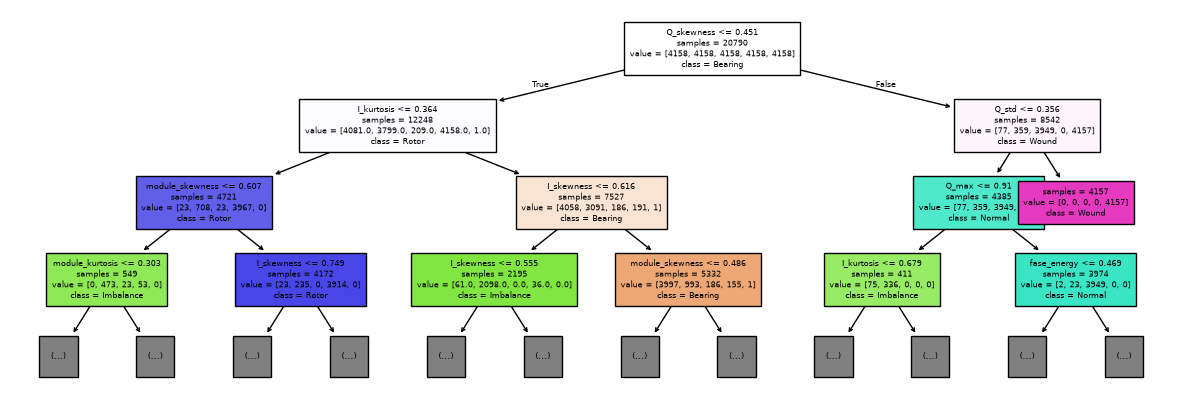

In [45]:
modelo = grid_search.best_estimator_.named_steps["modelo"]

plt.figure(figsize=(15, 5))

tree.plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=encoder_class.classes_,
    max_depth=3,
    fontsize=6,
    impurity=False,
    filled=True
)

<h1>Random Forest</h1>

In [46]:
pipeline_machineLearning = Pipeline([
    ("modelo", RandomForestClassifier())
])

param_grid = [
    {
        "modelo":[RandomForestClassifier(random_state=0)],
        "modelo__n_estimators": np.arange(2,20,2),
        "modelo__max_depth": [2,4,6,8]
        #"modelo__min_samples_split": [2, 5, 10],
        #"modelo__min_samples_leaf": [1, 2, 4]
    }
]

grid_search = GridSearchCV(
    pipeline_machineLearning,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_resampled, y_train_resampled)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo': [RandomForestC...andom_state=0)], 'modelo__max_depth': [2, 4, ...], 'modelo__n_estimators': array([ 2, 4..., 14, 16, 18])}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable add

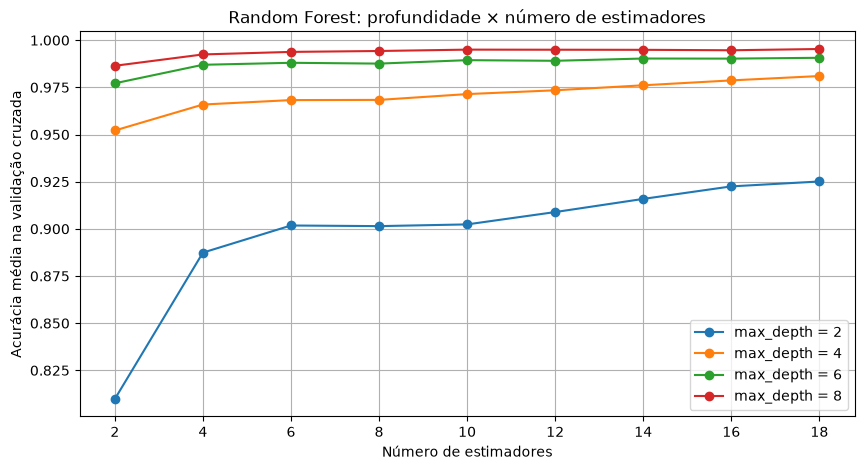

In [47]:
results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(10, 5))

for depth in sorted(results["param_modelo__max_depth"].dropna().unique()):
    dados = results[
        results["param_modelo__max_depth"] == depth
    ]

    plt.plot(
        dados["param_modelo__n_estimators"],
        dados["mean_test_score"],
        marker="o",
        label=f"max_depth = {depth}"
    )

plt.xlabel("Número de estimadores")
plt.ylabel("Acurácia média na validação cruzada")
plt.title("Random Forest: profundidade × número de estimadores")
plt.legend()
plt.grid()
plt.show()

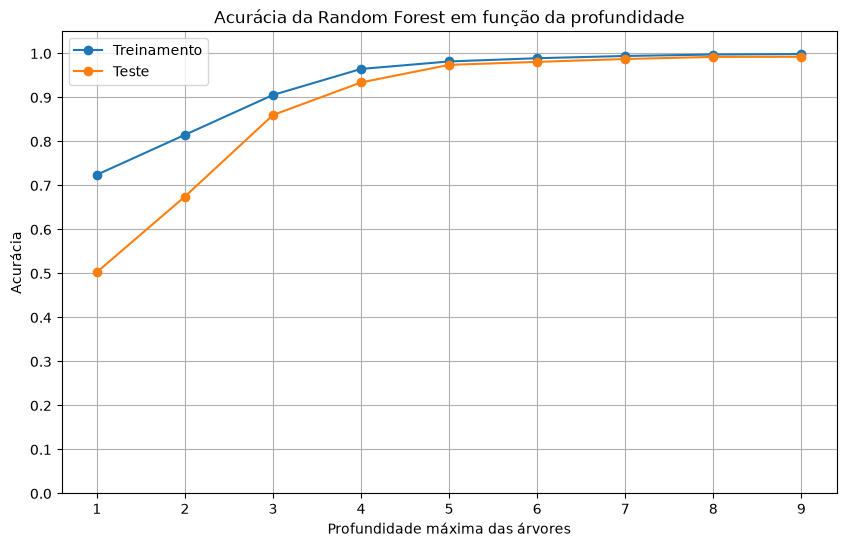

In [48]:
profundidades = range(1, 10)

acuracias_treino = []
acuracias_teste = []

for profundidade in profundidades:

    modelo = RandomForestClassifier(
        n_estimators=4,
        max_depth=profundidade,
        criterion='entropy',
        random_state=42
    )

    modelo.fit(X_train_resampled, y_train_resampled)

    # Acurácia no treinamento
    y_train_pred = modelo.predict(X_train_resampled)
    acc_train = accuracy_score(y_train_resampled, y_train_pred)

    # Acurácia no teste
    y_test_pred = modelo.predict(X_test)
    acc_test = accuracy_score(y_test, y_test_pred)

    acuracias_treino.append(acc_train)
    acuracias_teste.append(acc_test)

# Gráfico
plt.figure(figsize=(10, 6))

plt.plot(
    profundidades,
    acuracias_treino,
    marker="o",
    label="Treinamento"
)

plt.plot(
    profundidades,
    acuracias_teste,
    marker="o",
    label="Teste"
)

plt.xlabel("Profundidade máxima das árvores")
plt.ylabel("Acurácia")
plt.title("Acurácia da Random Forest em função da profundidade")
plt.ylim(0, 1.05)
plt.yticks(np.arange(0, 1.1, 0.1))
plt.xticks(profundidades)
plt.grid()
plt.legend()

In [49]:
print(pd.DataFrame(data=[profundidades,
    acuracias_treino,
    acuracias_teste]))

          0         1         2         3         4         5         6  \
0  1.000000  2.000000  3.000000  4.000000  5.000000  6.000000  7.000000   
1  0.724435  0.815152  0.905772  0.964887  0.981914  0.989274  0.994372   
2  0.503013  0.674861  0.860207  0.934201  0.974211  0.980959  0.987467   

          7         8  
0  8.000000  9.000000  
1  0.997643  0.998749  
2  0.992287  0.992528  


<h1>KNN<h1>

In [50]:
pipeline_machineLearning = Pipeline([
    ("modelo", KNeighborsClassifier())
])

param_grid = [
    {
        "modelo":[KNeighborsClassifier()],
        "modelo__n_neighbors": np.arange(1,100,2)
    }
]

grid_search = GridSearchCV(
    pipeline_machineLearning,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

grid_search.fit(X_train_resampled, y_train_resampled)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...lassifier())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo': [KNeighborsClassifier()], 'modelo__n_neighbors': array([ 1, 3..., 95, 97, 99])}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0

In [51]:
y_train_pred = grid_search.predict(X_train_resampled)
y_test_pred = grid_search.predict(X_test)
printDesempenho(y_train_resampled, y_train_pred, y_test, y_test_pred, encoder_class)

TREINAMENTO:
              precision    recall  f1-score   support

     Bearing     1.0000    1.0000    1.0000      4158
   Imbalance     1.0000    1.0000    1.0000      4158
      Normal     1.0000    1.0000    1.0000      4158
       Rotor     1.0000    1.0000    1.0000      4158
       Wound     1.0000    1.0000    1.0000      4158

    accuracy                         1.0000     20790
   macro avg     1.0000    1.0000    1.0000     20790
weighted avg     1.0000    1.0000    1.0000     20790

TESTE:
              precision    recall  f1-score   support

     Bearing     0.9933    0.9916    0.9924       594
   Imbalance     0.9949    0.9949    0.9949      1782
      Normal     0.9966    0.9966    0.9966       594
       Rotor     0.9950    0.9966    0.9958       594
       Wound     1.0000    1.0000    1.0000       585

    accuracy                         0.9957      4149
   macro avg     0.9960    0.9960    0.9960      4149
weighted avg     0.9957    0.9957    0.9957      4149



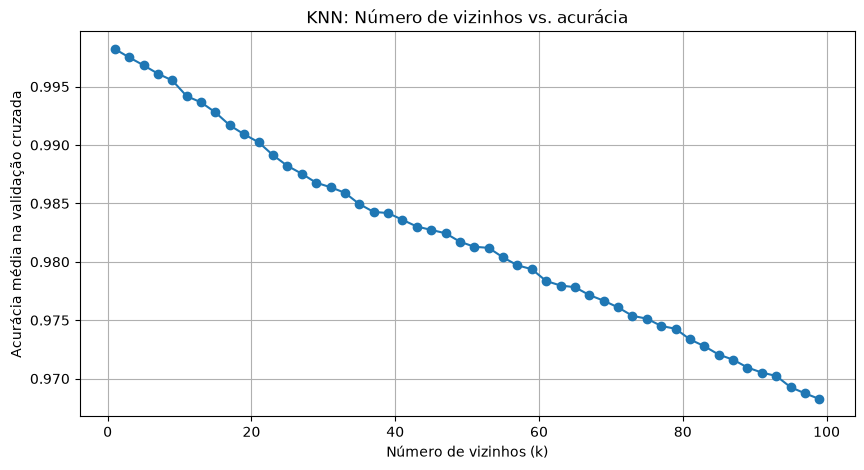

In [52]:
results = pd.DataFrame(grid_search.cv_results_)

plt.figure(figsize=(10, 5))

plt.plot(
    results["param_modelo__n_neighbors"],
    results["mean_test_score"],
    marker="o"
)

plt.xlabel("Número de vizinhos (k)")
plt.ylabel("Acurácia média na validação cruzada")
plt.title("KNN: Número de vizinhos vs. acurácia")
plt.grid()
plt.show()

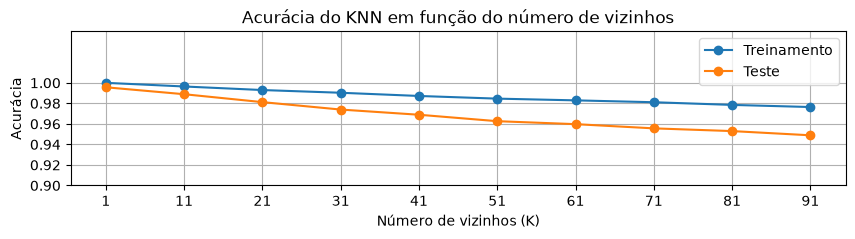

          0          1          2          3          4          5          6  \
0  1.000000  11.000000  21.000000  31.000000  41.000000  51.000000  61.000000   
1  1.000000   0.996441   0.992977   0.990332   0.987205   0.984608   0.982924   
2  0.995662   0.988913   0.981200   0.973970   0.968908   0.962642   0.959749   

           7          8          9  
0  71.000000  81.000000  91.000000  
1   0.981097   0.978499   0.976431  
2   0.955652   0.953001   0.948903  


In [53]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

valores_k = range(1,100, 10)

acuracias_treino = []
acuracias_teste = []

for k in valores_k:

    modelo = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo.fit(X_train_resampled, y_train_resampled)

    # Acurácia no treinamento
    y_train_pred = modelo.predict(X_train_resampled)
    acc_train = accuracy_score(y_train_resampled, y_train_pred)

    # Acurácia no teste
    y_test_pred = modelo.predict(X_test)
    acc_test = accuracy_score(y_test, y_test_pred)

    acuracias_treino.append(acc_train)
    acuracias_teste.append(acc_test)

# Gráfico
plt.figure(figsize=(10, 2))

plt.plot(
    valores_k,
    acuracias_treino,
    marker="o",
    label="Treinamento"
)

plt.plot(
    valores_k,
    acuracias_teste,
    marker="o",
    label="Teste"
)

plt.xlabel("Número de vizinhos (K)")
plt.ylabel("Acurácia")
plt.title("Acurácia do KNN em função do número de vizinhos")
plt.ylim(0.9, 1.05)
plt.yticks(np.arange(0.9, 1.02, 0.02))
plt.xticks(valores_k)
plt.grid()
plt.legend()

plt.show()

print(pd.DataFrame(data=[valores_k,
    acuracias_treino,
    acuracias_teste]))

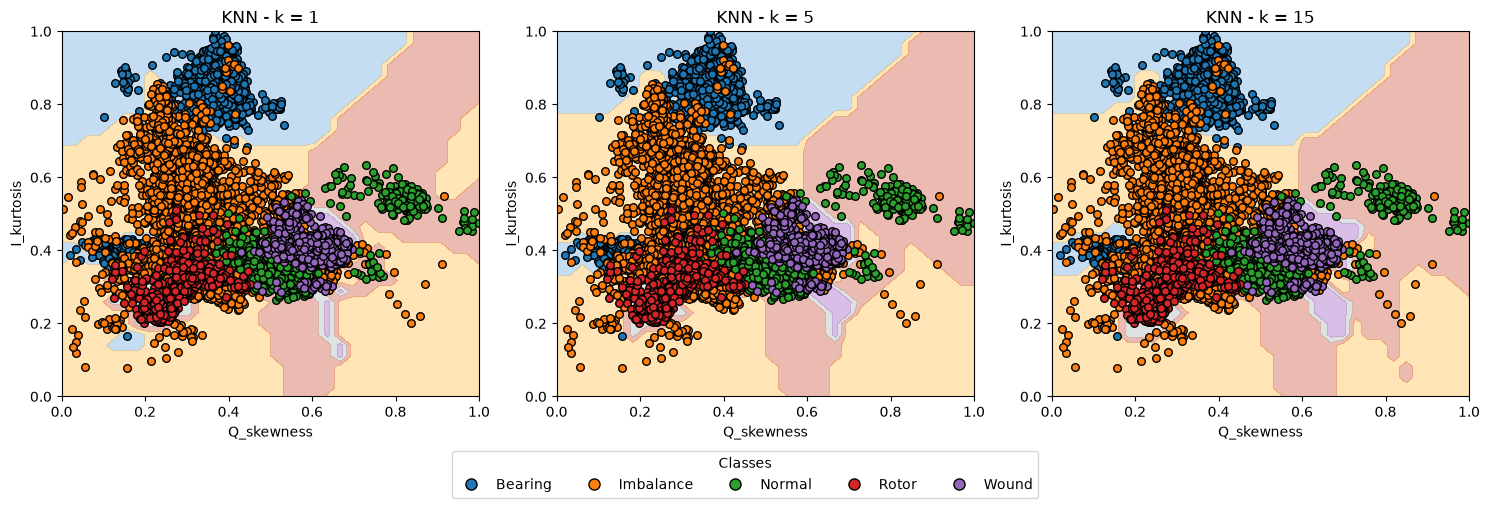

In [54]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np

feature1 = "Q_skewness"
feature2 = "I_kurtosis"

features = X.columns.tolist()

idx_f1 = features.get_loc(feature1) if hasattr(features, 'get_loc') else features.index(feature1)
idx_f2 = features.get_loc(feature2) if hasattr(features, 'get_loc') else features.index(feature2)

X_2d = X_train[:, [idx_f1, idx_f2]]

valores_k = [1, 5, 15]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Cores fixas para as classes
cores = plt.cm.tab10(np.arange(len(encoder_class.classes_)))

for ax, k in zip(axes, valores_k):

    modelo_knn = KNeighborsClassifier(
        n_neighbors=k
    )

    modelo_knn.fit(X_2d, y_train)

    DecisionBoundaryDisplay.from_estimator(
        modelo_knn,
        X_2d,
        response_method="predict",
        alpha=0.3,
        ax=ax
    )

    # Pontos das amostras
    for classe in np.unique(y_train):

        mask = y_train == classe

        ax.scatter(
            X_2d[mask, 0],
            X_2d[mask, 1],
            color=cores[classe],
            edgecolor="k",
            s=30
        )

    ax.set_title(f"KNN - k = {k}")
    ax.set_xlabel(feature1)
    ax.set_ylabel(feature2)

    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1)

# Criar legenda única
handles = []

for i, classe in enumerate(encoder_class.classes_):

    handles.append(
        Line2D(
            [0],
            [0],
            marker="o",
            linestyle="",
            markerfacecolor=cores[i],
            markeredgecolor="k",
            markersize=8,
            label=classe
        )
    )

fig.legend(
    handles=handles,
    title="Classes",
    loc="lower center",
    ncol=len(handles),
    bbox_to_anchor=(0.5, -0.02)
)

plt.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

In [55]:
X.columns.tolist()

['motorSpeed',
 'load',
 'I_kurtosis',
 'I_max',
 'I_median',
 'I_mode',
 'I_skewness',
 'Q_kurtosis',
 'Q_max',
 'Q_min',
 'Q_mode',
 'Q_skewness',
 'Q_std',
 'module_kurtosis',
 'module_max',
 'module_min',
 'module_mode',
 'module_skewness',
 'module_std',
 'fase_amplitude',
 'fase_energy',
 'fase_kurtosis',
 'fase_max',
 'fase_mean',
 'fase_mode',
 'fft_bandwidth',
 'fft_frequency_mean',
 'fft_frequency_median']

<h1>MLP</h1>

In [56]:
import tensorflow as tf
from tensorflow import keras

In [57]:
encoder_dense = OneHotEncoder(sparse_output=False)
encoder_dense.fit(y_encoded.reshape(-1,1))

y_dense_train = encoder_dense.transform(y_train_resampled.reshape(-1,1))
y_dense_test = encoder_dense.transform(y_test.reshape(-1,1))

In [58]:
num_features = encoder_data.n_features_in_
num_class = len(encoder_class.classes_)

model = keras.Sequential([
    keras.layers.Dense(int(num_features/2), activation="relu", input_shape=(num_features,)), #INPUT
    keras.layers.Dense(num_class, activation="softmax") #OUTPUT
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           406 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │            75 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 481 (1.88 KB)

 Trainable params: 481 (1.88 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.5575 - loss: 1.3899
Epoch 2/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.8711 - loss: 0.7108
Epoch 3/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9244 - loss: 0.3497
Epoch 4/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9425 - loss: 0.2368
Epoch 5/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9508 - loss: 0.1873
Epoch 6/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9553 - loss: 0.1584
Epoch 7/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9589 - loss: 0.1397
Epoch 8/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9613 - loss: 0.1269
Epoch 9/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9639 - loss: 0.1164
Epoch 10/10
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9647 - loss: 0.1085
650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9657 - loss: 0.1048
Acurácia: 96.57%


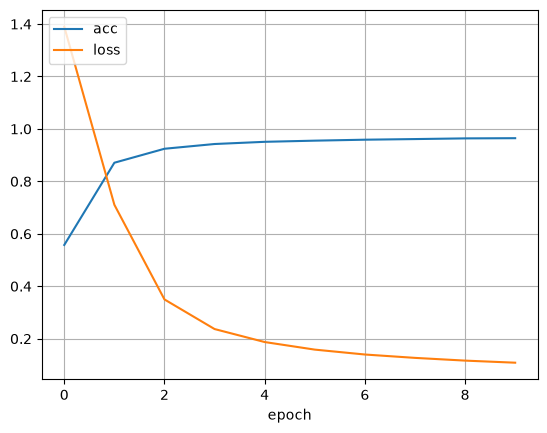

In [59]:
%matplotlib inline
history = model.fit(X_train_resampled, y_dense_train, epochs=10)
test_loss, test_acc = model.evaluate(X_train_resampled, y_dense_train)

print(f'Acurácia: {test_acc*100:.02f}%')

# Mostrar graficamente
plt.plot(history.history['accuracy'])
plt.plot(history.history['loss'])
plt.grid(True)
plt.xlabel('epoch')
plt.legend(['acc', 'loss'], loc='upper left')
plt.show()

In [60]:
y_train_pred = encoder_dense.inverse_transform(model.predict(X_train_resampled))
y_test_pred = encoder_dense.inverse_transform(model.predict(X_test))
printDesempenho(y_train_resampled, y_train_pred, y_test, y_test_pred, encoder_class)

650/650 ━━━━━━━━━━━━━━━━━━━━ 1s 831us/step
130/130 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  
TREINAMENTO:
              precision    recall  f1-score   support

     Bearing     0.9291    0.9584    0.9435      4158
   Imbalance     0.9299    0.8971    0.9132      4158
      Normal     0.9993    1.0000    0.9996      4158
       Rotor     0.9710    0.9735    0.9723      4158
       Wound     0.9990    0.9995    0.9993      4158

    accuracy                         0.9657     20790
   macro avg     0.9657    0.9657    0.9656     20790
weighted avg     0.9657    0.9657    0.9656     20790

TESTE:
              precision    recall  f1-score   support

     Bearing     0.8336    0.9360    0.8818       594
   Imbalance     0.9622    0.9007    0.9304      1782
      Normal     0.9966    1.0000    0.9983       594
       Rotor     0.9000    0.9545    0.9265       594
       Wound     0.9949    1.0000    0.9974       585

    accuracy                         0.9417      4149
   macro avg     0.9375  

<h1>MLP aaa</h1>


In [61]:
from sklearn.neural_network import MLPClassifier

In [65]:
encoder_data = MinMaxScaler()
encoder_class = LabelEncoder()
balanceamento = SMOTE(random_state=42)

X = df_dataset.select_dtypes(include="number")
Y = df_dataset['class']
x_encoded = encoder_data.fit_transform(X)
y_encoded = encoder_class.fit_transform(Y)

X_train, X_test, y_train, y_test = train_test_split(x_encoded, y_encoded, test_size=0.3, random_state=0, stratify=y_encoded)

#balanceamento
X_train_resampled, y_train_resampled = balanceamento.fit_resample(X_train, y_train)

In [66]:
arquiteturas = [
    (int(i),)
    for i in np.arange(2, 20, 2)
]
resultados = {}

for arquitetura in arquiteturas:

    modelo = MLPClassifier(
        hidden_layer_sizes=arquitetura,
        activation="relu",
        alpha=0.01,
        max_iter=1,
        warm_start=True,
        random_state=42
    )

    acuracia_treino = []
    acuracia_validacao = []

    for epoca in range(1, 51):

        modelo.fit(
            X_train_resampled,
            y_train_resampled
        )

        acuracia_treino.append(
            modelo.score(X_train, y_train)
        )

        acuracia_validacao.append(
            modelo.score(X_test, y_test)
        )

    resultados[arquitetura] = {
        "treino": acuracia_treino,
        "validacao": acuracia_validacao
    }

d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1) reached and the optimization hasn't converged yet.
  warnings.warn(
d:\MBA_IA_BIG_DATA\TCC\.venv\Lib\site-packages\sklearn\neural_ne

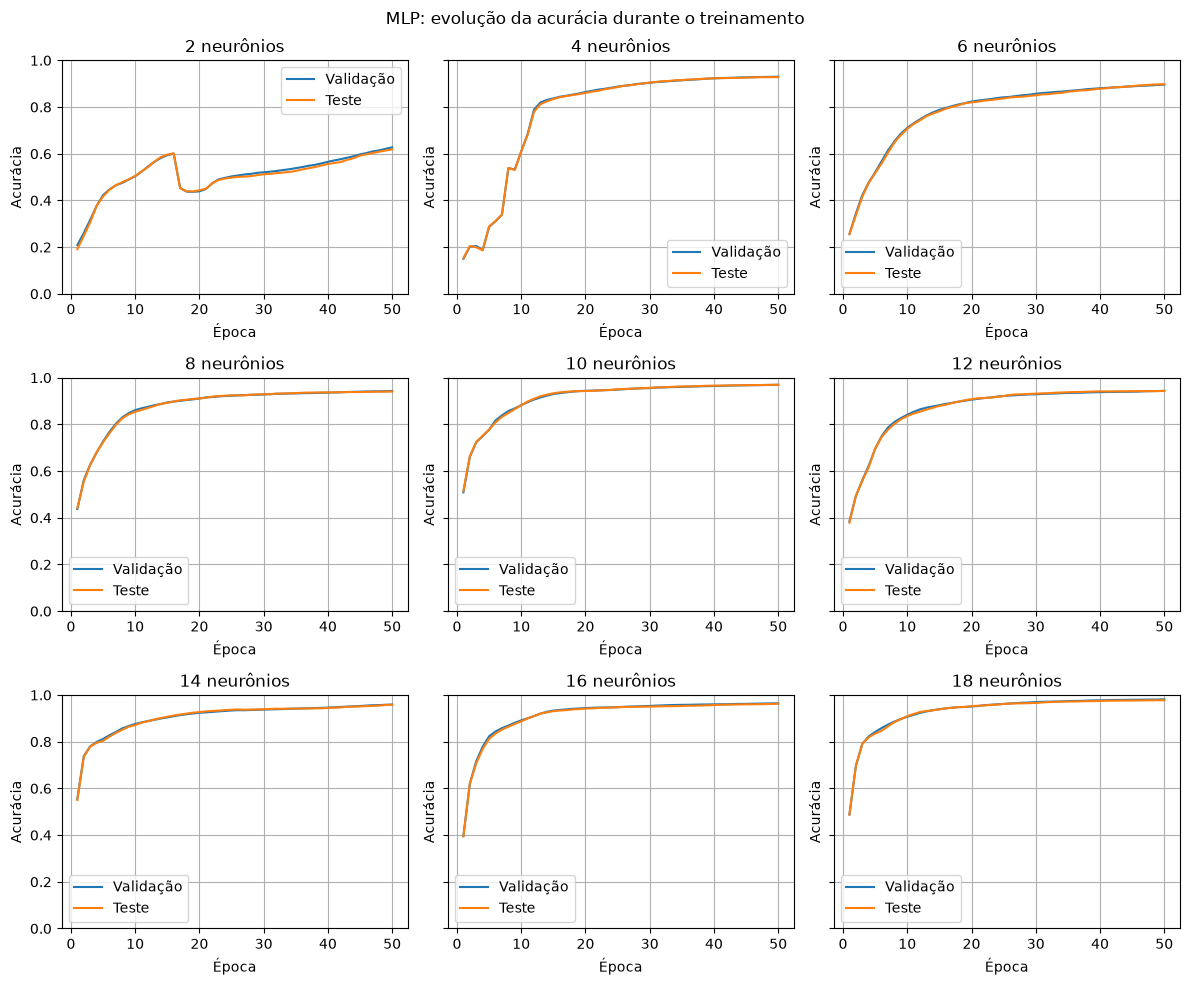

In [68]:
fig, axes = plt.subplots(
    3,
    int(len(arquiteturas)/3),
    figsize=(12, 10),
    sharey=True
)

for ax, arquitetura in zip(np.array(axes).flatten(), arquiteturas):

    epocas = np.arange(1, 51)

    ax.plot(
        epocas,
        resultados[arquitetura]["treino"],
        label="Validação"
    )

    ax.plot(
        epocas,
        resultados[arquitetura]["validacao"],
        label="Teste"
    )

    ax.set_title(
        f"{arquitetura[0]} neurônios"
    )

    ax.set_xlabel("Época")
    ax.set_ylabel("Acurácia")

    ax.set_ylim(0, 1)
    ax.grid()
    ax.legend()

plt.suptitle(
    "MLP: evolução da acurácia durante o treinamento"
)

plt.tight_layout()
plt.show()

   Quantidade de neurônios  Validação     Teste
0                        2   0.627311  0.618703
1                        4   0.930173  0.928175
2                        6   0.895879  0.897566
3                        8   0.942981  0.940468
4                       10   0.969631  0.969631
5                       12   0.943291  0.943119
6                       14   0.959095  0.958303
7                       16   0.964363  0.962401
8                       18   0.981510  0.977585


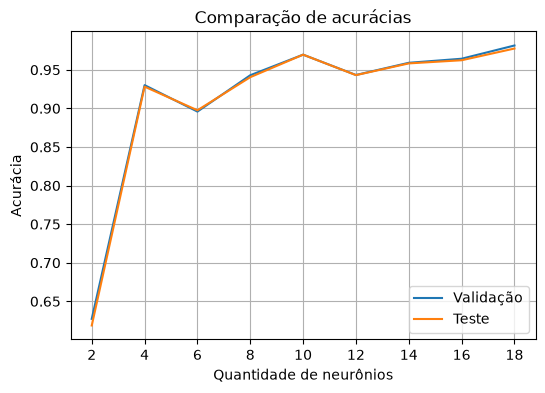

In [90]:
resultados[arquiteturas[1]]["treino"]
arqs = []
validacaos = []
testes = []
for arquitetura in arquiteturas:
    arqs.append(arquitetura[0])
    validacaos.append(resultados[arquitetura]["treino"][-1])
    testes.append(resultados[arquitetura]["validacao"][-1])

print(pd.DataFrame(data={
    "Quantidade de neurônios":arqs, "Validação":validacaos, "Teste": testes
}))

plt.figure(figsize=(6,4))
plt.plot(arqs, validacaos, label="Validação")
plt.plot(arqs, testes, label="Teste")
plt.grid()
plt.legend()
plt.xlabel("Quantidade de neurônios")
plt.ylabel("Acurácia")
plt.title("Comparação de acurácias")
plt.show()